# Рекомендательная система фильмов

В этом блокноте мы собираем и проверяем 4 основных подхода рекомендательных систем:
1. Популярные фильмы (взвешенный рейтинг IMDb) и фильтрация на знаниях (по жанру и году).
2. Фильтрация на контенте (похожие фильмы по жанрам и описанию через TF-IDF).
3. Коллаборативная фильтрация (корреляция и модель NearestNeighbors по фильмам и по пользователям).
4. Гибридный подход (объединение коллаборативной и контентной фильтрации) и обработка холодного старта.

В конце сохраняем готовые таблицы и модели в папку `models`, чтобы потом их использовал наш API.

## 1. Подключаем библиотеки

In [1]:
import ast
import os
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

%matplotlib inline

## 2. Загружаем данные

In [2]:
movies = pd.read_csv('data/movies_metadata.csv', low_memory=False)
links = pd.read_csv('data/links_small.csv')
ratings = pd.read_csv('data/ratings_small.csv')

In [3]:
movies[['id', 'title', 'genres', 'release_date', 'overview']].head()

,id,title,genres,release_date,overview
0,862,Toy Story,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",1995-10-30,"Led by Woody, Andy's toys live happily in his ..."
1,8844,Jumanji,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",1995-12-15,When siblings Judy and Peter discover an encha...
2,15602,Grumpier Old Men,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",1995-12-22,A family wedding reignites the ancient feud be...
3,31357,Waiting to Exhale,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",1995-12-22,"Cheated on, mistreated and stepped on, the wom..."
4,11862,Father of the Bride Part II,"[{'id': 35, 'name': 'Comedy'}]",1995-02-10,Just when George Banks has recovered from his ...


In [4]:
links.head()

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [5]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,31,2.5,1260759144
1,1,1029,3.0,1260759179
2,1,1061,3.0,1260759182
3,1,1129,2.0,1260759185
4,1,1172,4.0,1260759205


In [6]:
print('Фильмов в таблице:', movies.shape)
print('Связей в links_small:', links.shape)
print('Оценок в ratings_small:', ratings.shape)

Фильмов в таблице: (45466, 24)
Связей в links_small: (9125, 3)
Оценок в ratings_small: (100004, 4)


## 3. Очистка и объединение таблиц

In [7]:
# Оставляем только строки с нормальным числовым id и убираем повторы
movies = movies[movies['id'].str.isnumeric()].copy()
movies['id'] = movies['id'].astype(int)
movies = movies.drop_duplicates('id')

# Убираем пустые строки в таблице связей и приводим tmdbId к целому числу
links = links.dropna(subset=['tmdbId']).copy()
links['tmdbId'] = links['tmdbId'].astype(int)

# Соединяем фильмы со связями, чтобы получить movieId как в таблице оценок
movies = movies.merge(links, left_on='id', right_on='tmdbId')
movies = movies.drop_duplicates('movieId')

In [8]:
# Жанры записаны строкой вида [{'id': 16, 'name': 'Animation'}], достаем только названия
def parse_genres(text):
    try:
        items = ast.literal_eval(text)
        names = []
        for item in items:
            names.append(item['name'])
        return ', '.join(names)
    except Exception:
        return ''


movies['genres'] = movies['genres'].apply(parse_genres)
movies['year'] = movies['release_date'].fillna('').str[:4]
movies['overview'] = movies['overview'].fillna('')

movies = movies[['movieId', 'title', 'year', 'genres', 'overview']].copy()
movies.head()

,movieId,title,year,genres,overview
0,1,Toy Story,1995,"Animation, Comedy, Family","Led by Woody, Andy's toys live happily in his ..."
1,2,Jumanji,1995,"Adventure, Fantasy, Family",When siblings Judy and Peter discover an encha...
2,3,Grumpier Old Men,1995,"Romance, Comedy",A family wedding reignites the ancient feud be...
3,4,Waiting to Exhale,1995,"Comedy, Drama, Romance","Cheated on, mistreated and stepped on, the wom..."
4,5,Father of the Bride Part II,1995,Comedy,Just when George Banks has recovered from his ...


In [9]:
# Объединяем оценки с информацией о фильмах в одну общую таблицу df
df = ratings.merge(movies, on='movieId')
df.head()

,userId,movieId,rating,timestamp,title,year,genres,overview
0,1,31,2.5,1260759144,Dangerous Minds,1995,"Drama, Crime",Former Marine Louanne Johnson lands a gig teac...
1,1,1029,3.0,1260759179,Dumbo,1941,"Animation, Family",Dumbo is a baby elephant born with oversized e...
2,1,1061,3.0,1260759182,Sleepers,1996,"Crime, Drama, Thriller",Two gangsters seek revenge on the state jail w...
3,1,1129,2.0,1260759185,Escape from New York,1981,"Science Fiction, Action","In 1997, the island of Manhattan has been wall..."
4,1,1172,4.0,1260759205,Cinema Paradiso,1988,"Drama, Romance","A filmmaker recalls his childhood, when he fel..."


In [10]:
print('Размер общей таблицы:', df.shape)
print('Уникальных пользователей:', df['userId'].nunique())
print('Уникальных фильмов с оценками:', df['movieId'].nunique())

Размер общей таблицы: (99810, 8)
Уникальных пользователей: 671
Уникальных фильмов с оценками: 9025


### Небольшой анализ данных (графики)

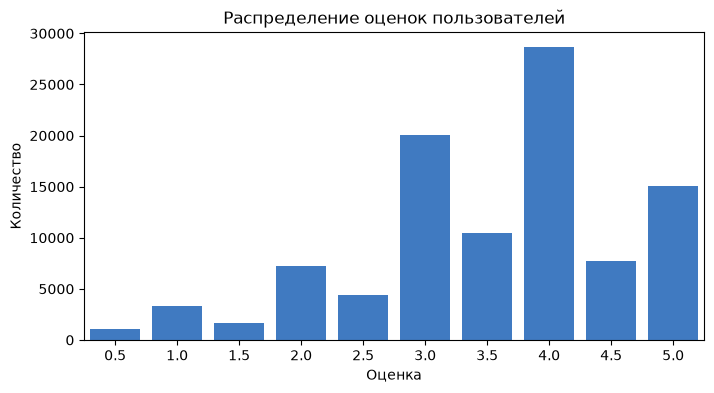

In [11]:
plt.figure(figsize=(8, 4))
sns.countplot(x='rating', data=df, color='#2a78d6')
plt.title('Распределение оценок пользователей')
plt.xlabel('Оценка')
plt.ylabel('Количество')
plt.show()

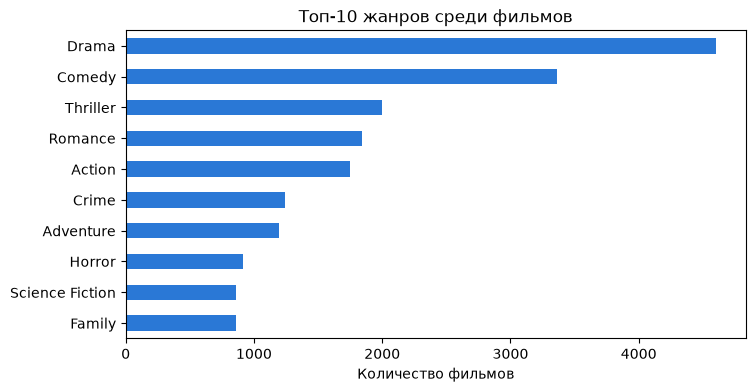

In [12]:
# Считаем, какие жанры встречаются чаще всего
genre_counts = {}
unique_movies = df.drop_duplicates('movieId')
for text in unique_movies['genres']:
    if text:
        for g in text.split(', '):
            if g in genre_counts:
                genre_counts[g] += 1
            else:
                genre_counts[g] = 1

top_genres = pd.Series(genre_counts).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
top_genres.sort_values().plot(kind='barh', color='#2a78d6')
plt.title('Топ-10 жанров среди фильмов')
plt.xlabel('Количество фильмов')
plt.show()

## 4. Подход 1: Популярные фильмы и фильтрация на знаниях

Сначала считаем средний рейтинг `avg_rating` и количество оценок `count_rating` для каждого фильма.
Затем применяем классическую формулу IMDb для взвешенного рейтинга, чтобы фильмы с 1-2 оценками не обгоняли известные фильмы с сотнями оценок:

`w_score = ((v * R) + (m * c)) / (v + m)`

- `v` - количество оценок у фильма
- `R` - средняя оценка фильма
- `m` - порог доверия (90-й процентиль числа оценок)
- `c` - средняя оценка по всем фильмам

In [13]:
avg_ratings = df.groupby('movieId')['rating'].mean().reset_index().rename(columns={'rating': 'avg_rating'})
cnt_ratings = df.groupby('movieId')['rating'].count().reset_index().rename(columns={'rating': 'count_rating'})

popularite = avg_ratings.merge(cnt_ratings, on='movieId')
popularite.head()

,movieId,avg_rating,count_rating
0,1,3.872470,247
1,2,3.401869,107
2,3,3.161017,59
3,4,2.384615,13
4,5,3.267857,56


In [14]:
# Добавляем к каждому фильму его статистику и сортируем по movieId
movies_df = movies.merge(popularite, on='movieId')
movies_df = movies_df.sort_values('movieId').reset_index(drop=True)

v = movies_df['count_rating']
R = movies_df['avg_rating']
m = v.quantile(0.90)
c = R.mean()

movies_df['w_score'] = ((v * R) + (m * c)) / (v + m)
print('Порог доверия m =', round(m, 2), ', средняя оценка c =', round(c, 2))

Порог доверия m = 28.0 , средняя оценка c = 3.29


In [15]:
movies_df['count_rating'].describe()

count    9025.000000
mean       11.059280
std        24.095433
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       341.000000
Name: count_rating, dtype: float64

In [16]:
pop_sort = movies_df.sort_values('w_score', ascending=False)
pop_sort[['title', 'year', 'genres', 'count_rating', 'avg_rating', 'w_score']].head(10)

,title,year,genres,count_rating,avg_rating,w_score
284,The Shawshank Redemption,1994,"Drama, Crime",311,4.487138,4.388276
692,The Godfather,1972,"Drama, Crime",200,4.487500,4.340464
48,The Usual Suspects,1995,"Drama, Crime, Thriller",201,4.370647,4.238540
472,Schindler's List,1993,"Drama, History, War",244,4.303279,4.198992
973,The Godfather: Part II,1974,"Drama, Crime",135,4.385185,4.197090
266,Pulp Fiction,1994,"Thriller, Crime",324,4.256173,4.179334
535,Fargo,1996,"Crime, Drama, Thriller",224,4.256696,4.149308
232,Star Wars,1977,"Adventure, Action, Science Fiction",291,4.221649,4.139892
949,The Empire Strikes Back,1980,"Adventure, Action, Science Fiction",234,4.232906,4.132159
2283,American Beauty,1999,Drama,220,4.236364,4.129539


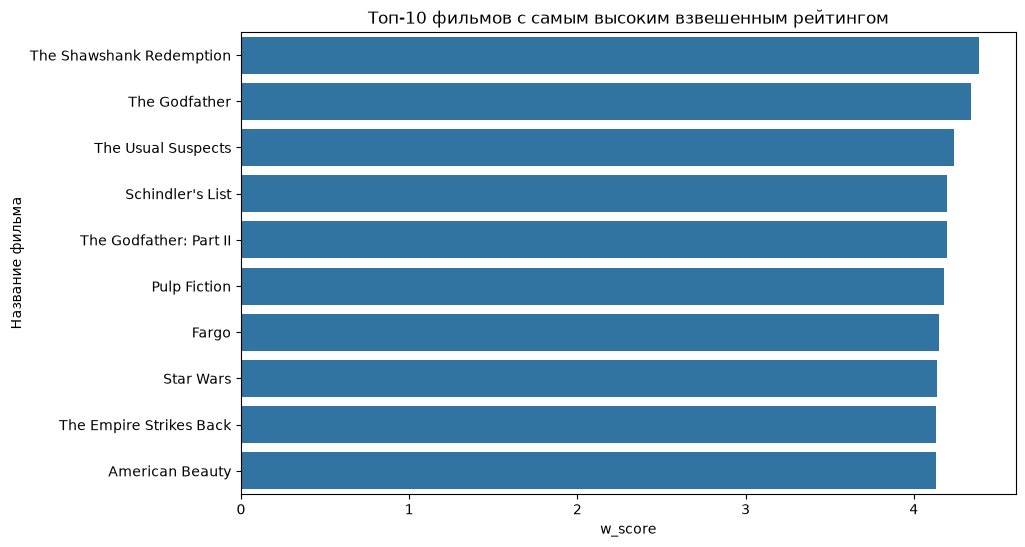

In [17]:
top_10_movies = pop_sort.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='w_score', y='title', data=top_10_movies)
plt.xlabel('w_score')
plt.ylabel('Название фильма')
plt.title('Топ-10 фильмов с самым высоким взвешенным рейтингом')
plt.show()

### Фильтрация на знаниях

Если пользователь заранее задает конкретные требования (например, жанр и год выхода фильма), мы фильтруем каталог по этим признакам и сортируем по `w_score`.

In [18]:
def filter_by_knowledge(genre='', min_year=0, n=10):
    result = movies_df.copy()
    if genre:
        result = result[result['genres'].str.contains(genre, case=False, regex=False)]
    if min_year > 0:
        years = pd.to_numeric(result['year'], errors='coerce').fillna(0)
        result = result[years >= min_year]
    result = result.sort_values('w_score', ascending=False).head(n)
    return result[['movieId', 'title', 'year', 'genres', 'w_score']]


# Пример: лучшие комедии начиная с 2000 года
filter_by_knowledge(genre='Comedy', min_year=2000, n=10)

,movieId,title,year,genres,w_score
3846,4973,Amélie,2001,"Comedy, Romance",3.948534
2775,3481,High Fidelity,2000,"Comedy, Drama, Romance, Music",3.798497
3795,4886,"Monsters, Inc.",2001,"Animation, Comedy, Family",3.779277
3412,4306,Shrek,2001,"Adventure, Animation, Comedy, Family, Fantasy",3.770424
6588,50872,Ratatouille,2007,"Animation, Comedy, Family, Fantasy",3.760065
7506,78499,Toy Story 3,2010,"Animation, Family, Comedy",3.758938
3223,4027,"O Brother, Where Art Thou?",2000,"Action, Adventure, Comedy",3.742949
6428,46578,Little Miss Sunshine,2006,"Comedy, Drama",3.741593
7191,68954,Up,2009,"Animation, Comedy, Family, Adventure",3.737367
7933,92259,The Intouchables,2011,"Drama, Comedy",3.720467


## 5. Подход 2: Фильтрация на контенте

Рекомендации строятся только по свойствам самого фильма (жанры и описание сюжета).
Склеиваем жанры и описание в одну строку, переводим текст в числовые векторы с помощью `TfidfVectorizer` и ищем самые похожие фильмы через косинусное сходство (`cosine_similarity`).

In [19]:
movies_df['content'] = movies_df['genres'] + ' ' + movies_df['overview']

tfidf = TfidfVectorizer(stop_words='english', max_features=10000)
tfidf_matrix = tfidf.fit_transform(movies_df['content'])
print('Размер матрицы TF-IDF:', tfidf_matrix.shape)

Размер матрицы TF-IDF: (9025, 10000)


In [20]:
def recommend_content(movie_title, n=10):
    found = movies_df[movies_df['title'] == movie_title]
    if found.empty:
        return f"Фильм '{movie_title}' не найден."

    idx = found.index[0]
    sims = cosine_similarity(tfidf_matrix[idx], tfidf_matrix)[0]
    similar_items = sorted(list(enumerate(sims)), key=lambda x: x[1], reverse=True)[1:n + 1]

    result = []
    for i, score in similar_items:
        row = movies_df.iloc[i]
        result.append({
            'movieId': int(row['movieId']),
            'title': row['title'],
            'year': row['year'],
            'genres': row['genres'],
            'similarity': round(float(score), 3)
        })
    return pd.DataFrame(result)

In [21]:
recommend_content('Toy Story')

,movieId,title,year,genres,similarity
0,78499,Toy Story 3,2010,"Animation, Family, Comedy",0.533
1,3114,Toy Story 2,1999,"Animation, Comedy, Family",0.445
2,35836,The 40 Year Old Virgin,2005,"Comedy, Romance",0.322
3,51174,Factory Girl,2006,Drama,0.189
4,3174,Man on the Moon,1999,"Comedy, Drama, Romance",0.189
5,7096,Rivers and Tides,2001,"Documentary, Foreign",0.189
6,1103,Rebel Without a Cause,1955,Drama,0.182
7,49220,For Your Consideration,2006,"Comedy, Drama",0.176
8,2041,Condorman,1981,"Comedy, Action, Adventure",0.167
9,490,Malice,1993,"Drama, Crime",0.160


In [22]:
recommend_content('The Dark Knight')

,movieId,title,year,genres,similarity
0,91529,The Dark Knight Rises,2012,"Action, Crime, Drama, Thriller",0.356
1,1377,Batman Returns,1992,"Action, Fantasy",0.289
2,153,Batman Forever,1995,"Action, Crime, Fantasy",0.271
3,79274,Batman: Under the Red Hood,2010,"Action, Animation",0.260
4,99813,"Batman: The Dark Knight Returns, Part 2",2013,"Action, Animation",0.232
5,98124,"Batman: The Dark Knight Returns, Part 1",2012,"Action, Animation",0.228
6,592,Batman,1989,"Fantasy, Action",0.206
7,90603,Batman: Year One,2011,"Action, Adventure, Animation, Crime, Science F...",0.201
8,33794,Batman Begins,2005,"Action, Crime, Drama",0.199
9,3213,Batman: Mask of the Phantasm,1993,"Action, Adventure, Animation, Family",0.198


## 6. Подход 3: Коллаборативная фильтрация

Строим матрицу оценок `users_pivot`: строки - пользователи, столбцы - фильмы, в клетках - оценки (0, если пользователь фильм не оценивал).

In [23]:
users_pivot = df.pivot_table(index='userId', columns='movieId', values='rating')
users_pivot.fillna(0, inplace=True)
print('Размер матрицы users_pivot:', users_pivot.shape)
print('Порядок фильмов совпадает с movies_df:', list(users_pivot.columns) == list(movies_df['movieId']))
users_pivot.head()

Размер матрицы users_pivot: (671, 9025)
Порядок фильмов совпадает с movies_df: True


movieId,1,2,3,4,5,6,7,8,9,10,...,160718,161084,161155,161594,161830,161918,161944,162542,162672,163949
userId,,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Способ А: Похожие фильмы через корреляцию (corrwith)

In [24]:
# Для корреляции берем популярные фильмы с количеством оценок >= 30
popular_ids = movies_df[movies_df['count_rating'] >= 30]['movieId'].tolist()
popular_pivot = users_pivot[popular_ids]

def same_movies_corr(movie_id, n=10):
    movie_votes = popular_pivot[movie_id]
    similar_with = popular_pivot.corrwith(movie_votes)
    corr_df = pd.DataFrame(similar_with, columns=['correlation'])
    corr_df = corr_df.drop(movie_id, errors='ignore')
    corr_df = corr_df.sort_values('correlation', ascending=False).head(n)
    corr_df = corr_df.merge(movies_df[['movieId', 'title', 'genres']], left_index=True, right_on='movieId')
    return corr_df[['movieId', 'title', 'genres', 'correlation']]


# Похожие на Toy Story (movieId = 1)
same_movies_corr(1)

,movieId,title,genres,correlation
2501,3114,Toy Story 2,"Animation, Comedy, Family",0.474141
1862,2355,A Bug's Life,"Adventure, Animation, Comedy, Family",0.393799
1015,1265,Groundhog Day,"Romance, Fantasy, Drama, Comedy",0.372371
3795,4886,"Monsters, Inc.","Animation, Comedy, Family",0.366277
641,780,Independence Day,"Action, Adventure, Science Fiction",0.356876
4595,6377,Finding Nemo,"Animation, Family",0.348941
5600,8961,The Incredibles,"Action, Adventure, Animation, Family",0.346066
3412,4306,Shrek,"Adventure, Animation, Comedy, Family, Fantasy",0.344068
863,1073,Willy Wonka & the Chocolate Factory,"Family, Fantasy",0.320002
232,260,Star Wars,"Adventure, Action, Science Fiction",0.318531


### Способ Б: Похожие фильмы через NearestNeighbors (Item-based)

In [25]:
movie_sparse = csr_matrix(users_pivot.values).T
model_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_knn.fit(movie_sparse)


def find_similar_movies(movie_id, num_neighbors=10):
    movie_index = users_pivot.columns.get_loc(movie_id)
    movie_vector = movie_sparse[movie_index]
    distances, indices = model_knn.kneighbors(movie_vector, n_neighbors=num_neighbors + 1)

    similar_indices = indices[0][1:]
    similar_distances = distances[0][1:]

    result = []
    for pos, dist in zip(similar_indices, similar_distances):
        row = movies_df.iloc[pos]
        result.append({
            'movieId': int(row['movieId']),
            'title': row['title'],
            'year': row['year'],
            'genres': row['genres'],
            'similarity': round(float(1 - dist), 3)
        })
    return pd.DataFrame(result)

In [26]:
# Похожие на Toy Story (movieId = 1)
find_similar_movies(1)

,movieId,title,year,genres,similarity
0,3114,Toy Story 2,1999,"Animation, Comedy, Family",0.595
1,260,Star Wars,1977,"Adventure, Action, Science Fiction",0.576
2,356,Forrest Gump,1994,"Comedy, Drama, Romance",0.565
3,780,Independence Day,1996,"Action, Adventure, Science Fiction",0.563
4,1265,Groundhog Day,1993,"Romance, Fantasy, Drama, Comedy",0.548
5,1270,Back to the Future,1985,"Adventure, Comedy, Science Fiction, Family",0.537
6,480,Jurassic Park,1993,"Adventure, Science Fiction",0.535
7,4306,Shrek,2001,"Adventure, Animation, Comedy, Family, Fantasy",0.533
8,1210,Return of the Jedi,1983,"Adventure, Action, Science Fiction",0.529
9,296,Pulp Fiction,1994,"Thriller, Crime",0.527


In [27]:
# Похожие на The Matrix (movieId = 2571)
find_similar_movies(2571)

,movieId,title,year,genres,similarity
0,4993,The Lord of the Rings: The Fellowship of the Ring,2001,"Adventure, Fantasy, Action",0.692
1,5952,The Lord of the Rings: The Two Towers,2002,"Adventure, Fantasy, Action",0.674
2,2959,Fight Club,1999,Drama,0.655
3,1270,Back to the Future,1985,"Adventure, Comedy, Science Fiction, Family",0.652
4,7153,The Lord of the Rings: The Return of the King,2003,"Adventure, Fantasy, Action",0.647
5,1196,The Empire Strikes Back,1980,"Adventure, Action, Science Fiction",0.646
6,260,Star Wars,1977,"Adventure, Action, Science Fiction",0.635
7,2028,Saving Private Ryan,1998,"Drama, History, War",0.630
8,3578,Gladiator,2000,"Action, Drama, Adventure",0.621
9,4306,Shrek,2001,"Adventure, Animation, Comedy, Family, Fantasy",0.620


### Способ В: Похожие пользователи через NearestNeighbors (User-based)

In [28]:
def find_favorite_movies(user_id, num_movies=10):
    user_ratings = users_pivot.loc[user_id]
    top_movies = user_ratings[user_ratings > 0].sort_values(ascending=False).head(num_movies)
    result = []
    for mid, rating in top_movies.items():
        row = movies_df[movies_df['movieId'] == mid].iloc[0]
        result.append({'movieId': int(mid), 'title': row['title'], 'rating': float(rating)})
    return pd.DataFrame(result)


find_favorite_movies(1)

,movieId,title,rating
0,1953,The French Connection,4.0
1,2105,Tron,4.0
2,1172,Cinema Paradiso,4.0
3,1339,Dracula,3.5
4,3671,Blazing Saddles,3.0
5,2150,The Gods Must Be Crazy,3.0
6,1061,Sleepers,3.0
7,1029,Dumbo,3.0
8,1371,Star Trek: The Motion Picture,2.5
9,31,Dangerous Minds,2.5


In [29]:
user_sparse = csr_matrix(users_pivot.values)
model_user_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_user_knn.fit(user_sparse)


def find_user_recommendations(user_id, num_neighbors=20, num_movies=10):
    user_index = users_pivot.index.get_loc(user_id)

    # 1. Ищем похожих пользователей
    distances, indices = model_user_knn.kneighbors(
        user_sparse[user_index],
        n_neighbors=num_neighbors + 1
    )
    similar_user_indices = indices[0][1:]
    similar_distances = distances[0][1:]

    # 2. Берем оценки похожих пользователей
    similar_ratings = users_pivot.iloc[similar_user_indices]

    # 3. Взвешенное среднее: чем меньше расстояние до соседа, тем больше его вес
    weights = 1 / (similar_distances + 1e-9)
    weighted_scores = similar_ratings.T.dot(weights) / weights.sum()

    # 4. Убираем фильмы, которые пользователь уже смотрел
    target_ratings = users_pivot.iloc[user_index]
    unseen = target_ratings[target_ratings == 0].index
    candidates = weighted_scores.loc[unseen]

    # 5. Берем топ-N фильмов
    top_movies = candidates.sort_values(ascending=False).head(num_movies)

    result = []
    for mid, score in top_movies.items():
        row = movies_df[movies_df['movieId'] == mid].iloc[0]
        result.append({
            'movieId': int(mid),
            'title': row['title'],
            'year': row['year'],
            'genres': row['genres'],
            'score': round(float(score), 3)
        })
    return pd.DataFrame(result)

In [30]:
find_user_recommendations(1)

,movieId,title,year,genres,score
0,1221,The Godfather: Part II,1974,"Drama, Crime",2.174
1,608,Fargo,1996,"Crime, Drama, Thriller",2.085
2,858,The Godfather,1972,"Drama, Crime",2.055
3,1193,One Flew Over the Cuckoo's Nest,1975,Drama,2.046
4,1225,Amadeus,1984,"Drama, History, Music",1.969
5,318,The Shawshank Redemption,1994,"Drama, Crime",1.953
6,953,It's a Wonderful Life,1946,"Drama, Family, Fantasy",1.931
7,1276,Cool Hand Luke,1967,"Crime, Drama",1.903
8,1207,To Kill a Mockingbird,1962,"Crime, Drama",1.874
9,527,Schindler's List,1993,"Drama, History, War",1.829


In [31]:
find_user_recommendations(4)

,movieId,title,year,genres,score
0,318,The Shawshank Redemption,1994,"Drama, Crime",3.674
1,595,Beauty and the Beast,1991,"Romance, Family, Animation, Fantasy, Music",3.633
2,593,The Silence of the Lambs,1991,"Crime, Drama, Thriller",3.571
3,2028,Saving Private Ryan,1998,"Drama, History, War",3.550
4,527,Schindler's List,1993,"Drama, History, War",3.478
5,608,Fargo,1996,"Crime, Drama, Thriller",3.441
6,592,Batman,1989,"Fantasy, Action",3.086
7,1,Toy Story,1995,"Animation, Comedy, Family",3.073
8,110,Braveheart,1995,"Action, Drama, History, War",3.058
9,2571,The Matrix,1999,"Action, Science Fiction",3.018


## 7. Подход 4: Гибридный подход и холодный старт

Идея гибридного подхода: берем отдельно оценки коллаборативной фильтрации (от 0 до 1) и контентной фильтрации (от 0 до 1) и объединяем их:
`hybrid_score = 0.5 * collab_score + 0.5 * content_score`

Если пользователь новый и у него еще нет оценок (проблема холодного старта), мы возвращаем популярные фильмы по `w_score`.

In [32]:
def recommend_hybrid_movie(movie_id, n=5):
    idx = movies_df[movies_df['movieId'] == movie_id].index[0]

    collab_sim = cosine_similarity(movie_sparse[idx], movie_sparse)[0]
    content_sim = cosine_similarity(tfidf_matrix[idx], tfidf_matrix)[0]
    hybrid_score = 0.5 * collab_sim + 0.5 * content_sim

    hybrid_score[idx] = -1
    top_indices = np.argsort(hybrid_score)[::-1][:n]

    result = []
    for i in top_indices:
        row = movies_df.iloc[i]
        result.append({
            'movieId': int(row['movieId']),
            'title': row['title'],
            'year': row['year'],
            'genres': row['genres'],
            'hybrid_score': round(float(hybrid_score[i]), 3)
        })
    return pd.DataFrame(result)


recommend_hybrid_movie(1)

,movieId,title,year,genres,hybrid_score
0,3114,Toy Story 2,1999,"Animation, Comedy, Family",0.520
1,78499,Toy Story 3,2010,"Animation, Family, Comedy",0.456
2,35836,The 40 Year Old Virgin,2005,"Comedy, Romance",0.314
3,318,The Shawshank Redemption,1994,"Drama, Crime",0.302
4,4886,"Monsters, Inc.",2001,"Animation, Comedy, Family",0.302


In [33]:
def recommend_hybrid_user(user_id, num_neighbors=20, n=10):
    # Проверка холодного старта: если пользователя нет или оценок 0, даем популярные фильмы
    if user_id not in users_pivot.index or users_pivot.loc[user_id].sum() == 0:
        return pop_sort[['movieId', 'title', 'year', 'genres', 'w_score']].head(n)

    user_index = users_pivot.index.get_loc(user_id)
    distances, indices = model_user_knn.kneighbors(user_sparse[user_index], n_neighbors=num_neighbors + 1)
    similar_user_indices = indices[0][1:]
    similar_distances = distances[0][1:]

    similar_ratings = users_pivot.iloc[similar_user_indices]
    weights = 1 / (similar_distances + 1e-9)
    collab_scores = (similar_ratings.T.dot(weights) / weights.sum()).values

    # Приводим коллаборативный балл к диапазону от 0 до 1
    if collab_scores.max() > 0:
        collab_norm = collab_scores / collab_scores.max()
    else:
        collab_norm = collab_scores

    # Контентный балл считаем по фильмам, которые понравились пользователю (оценка >= 4)
    user_arr = users_pivot.iloc[user_index].values
    liked_indices = np.where(user_arr >= 4)[0]
    if len(liked_indices) == 0:
        liked_indices = [int(np.argmax(user_arr))]

    content_scores = np.zeros(len(movies_df))
    for idx in liked_indices:
        content_scores += cosine_similarity(tfidf_matrix[idx], tfidf_matrix)[0]
    content_scores = content_scores / len(liked_indices)

    # Объединитель: 50% коллаборативная + 50% контентная
    hybrid_scores = 0.5 * collab_norm + 0.5 * content_scores
    hybrid_scores[user_arr > 0] = -1

    top_indices = np.argsort(hybrid_scores)[::-1][:n]
    result = []
    for i in top_indices:
        row = movies_df.iloc[i]
        result.append({
            'movieId': int(row['movieId']),
            'title': row['title'],
            'year': row['year'],
            'genres': row['genres'],
            'hybrid_score': round(float(hybrid_scores[i]), 3)
        })
    return pd.DataFrame(result)


print('Пример гибридной рекомендации для пользователя 1:')
recommend_hybrid_user(1)

Пример гибридной рекомендации для пользователя 1:


,movieId,title,year,genres,hybrid_score
0,1221,The Godfather: Part II,1974,"Drama, Crime",0.468
1,608,Fargo,1996,"Crime, Drama, Thriller",0.448
2,1193,One Flew Over the Cuckoo's Nest,1975,Drama,0.445
3,858,The Godfather,1972,"Drama, Crime",0.444
4,1225,Amadeus,1984,"Drama, History, Music",0.422
5,318,The Shawshank Redemption,1994,"Drama, Crime",0.420
6,953,It's a Wonderful Life,1946,"Drama, Family, Fantasy",0.415
7,1207,To Kill a Mockingbird,1962,"Crime, Drama",0.409
8,1276,Cool Hand Luke,1967,"Crime, Drama",0.409
9,527,Schindler's List,1993,"Drama, History, War",0.392


In [34]:
print('Пример холодного старта для нового пользователя 999:')
recommend_hybrid_user(999, n=5)

Пример холодного старта для нового пользователя 999:


,movieId,title,year,genres,w_score
284,318,The Shawshank Redemption,1994,"Drama, Crime",4.388276
692,858,The Godfather,1972,"Drama, Crime",4.340464
48,50,The Usual Suspects,1995,"Drama, Crime, Thriller",4.238540
472,527,Schindler's List,1993,"Drama, History, War",4.198992
973,1221,The Godfather: Part II,1974,"Drama, Crime",4.197090


## 8. Сохраняем готовые данные и модели в папку `models/`

In [35]:
os.makedirs('models', exist_ok=True)

movies_to_save = movies_df[['movieId', 'title', 'year', 'genres', 'overview',
                            'avg_rating', 'count_rating', 'w_score']].copy()

with open('models/movies.pkl', 'wb') as f:
    pickle.dump(movies_to_save, f)

with open('models/users_pivot.pkl', 'wb') as f:
    pickle.dump(users_pivot.astype('float32'), f)

with open('models/tfidf_matrix.pkl', 'wb') as f:
    pickle.dump(tfidf_matrix, f)

with open('models/model_knn.pkl', 'wb') as f:
    pickle.dump(model_knn, f)

with open('models/model_user_knn.pkl', 'wb') as f:
    pickle.dump(model_user_knn, f)

print('Сохраненные файлы в models/:', sorted(os.listdir('models')))

Сохраненные файлы в models/: ['model_knn.pkl', 'model_user_knn.pkl', 'movies.pkl', 'tfidf_matrix.pkl', 'users_pivot.pkl']
